In [1]:
import pandas as pd
import numpy as np

# Causal graph
import dowhy
from dowhy import CausalModel
import matplotlib.pyplot as plt

# Gaussian mixture model
import itertools
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Scikit-Learn Imports
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor)

# Model Selection & Metrics
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Linear Model
from scipy.special import expit, logit
import statsmodels.api as sm

# Neural Network
import tensorflow as tf
from tensorflow import keras

# Ale plot
import math
from PyALE import ale
from alibi.explainers import ALE

C:\Users\ACER\anaconda3\envs\FDP\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


tensorflow:WARNING: From C:\Users\ACER\anaconda3\envs\FDP\lib\site-packages\alibi\explainers\cem.py:35: The name tf.Session is deprecated. Please use tf.compat.v1.Session instead.



# TARGETED MAXIMUM LIKELIHOOD ESTIMATOR

**TMLE** shares the double robustness of AIPW—achieving consistency if either the outcome model $\mu(X,T)$ or the propensity score $\hat{e}(X)$ is correct—but fundamentally differs in its architecture. Instead of applying a post-hoc additive IPW correction, TMLE incorporates the propensity score directly into the outcome predictions via a targeted "clever covariate" $H(T,X)$. This fluctuation step updates the initial predictions, allowing the final estimate to remain a proper substitution estimator. Although originally formulated for binary outcomes, TMLE easily extends to continuous variables by linearly scaling the target into $[0,1]$. By folding the robustness correction internally, it naturally respects outcome bounds via a logit link, offering superior finite-sample efficiency for machine learning pipelines.

# TMLE STEPS
- Preprocess Step: **Scaling** the Target into [0,1]
  
- Step 1: Model Fitting (Outcome Model): $T$:$$\mu(X, T) = \mathbb{E}[Y \mid X, T]$$
- Step 2: Generating Initial Predictions: with the model $\mu$, we calculate three predictions:$\hat{y}_t = \mu(X, T = t)$,$\hat{y}_0 = \mu(X, T = 0)$,$\hat{y}_1 = \mu(X, T = 1)$
- Step 3: Propensity Score Estimation: (Propensity Score):$$\hat{e}(X) = P(T = 1 \mid X)$$ (bayesian)
- Step 4: Computing the "Clever Covariate"S$H(T, X)$, definita come:$$H(T, X) = \frac{\mathbb{I}(T = 1)}{\hat{e}(X)} - \frac{\mathbb{I}(T = 0)}{1 - \hat{e}(X)}$$(efficient influence curve).
- Step 5: Fluctuation Parameter Estimation ($\hat{\epsilon}$): Fit a logistic regression to fluctuate the initial predictions on the logit scale:
$$\text{logit}(P(Y=1)) = \text{offset} + \epsilon \cdot H(T,X)$$

$$\text{offset} = \text{logit}(\hat{y}_t)$$

The intercept is fixed (typically $0$, or $-1$ depending on the framework's parametrization), and the offset is set to the fixed vector c — the logit of the initial outcome-model prediction. This leaves $\epsilon$ as the **only free parameter** being estimated: the regression is not learning a new predictive relationship, it is finding the single scalar correction needed to move the initial predictions just enough to satisfy the efficient influence curve equation, using the clever covariate $H(T,X)$ as its sole regressor.

- Step 6: Updating Predictions: Update the predicted probabilities from Step 2 using $\hat{\epsilon}$ and the inverse logit (expit/sigmoid) transform:
$$\hat{y}_t^* = \text{expit}\big(\text{logit}(\hat{y}_t) + \hat{\epsilon}\cdot H(T=t,X)\big)$$
$$\hat{y}_0^* = \text{expit}\left(\text{logit}(\hat{y}_0) + \hat{\epsilon}\cdot\left(-\frac{1}{1-\hat{e}(X)}\right)\right)$$
$$\hat{y}_1^* = \text{expit}\left(\text{logit}(\hat{y}_1) + \hat{\epsilon}\cdot\left(\frac{1}{\hat{e}(X)}\right)\right)$$

Each potential outcome prediction is nudged in the direction dictated by the propensity score, with the magnitude of the correction scaled by $\hat\epsilon$: this is the step where the propensity-score information is actually absorbed into the outcome predictions.
- Step 7: Computing the ATE: $$\hat{\tau}_{ATE} = \frac{1}{N}\sum_{i=1}^{N}\left(\hat{y}_{1,i}^* - \hat{y}_{0,i}^*\right)$$
- Step 8: Revert the ATE in the original target scale: $ATE = \hat{\tau}_{ATE} * (y_{max}-y_{min})$

(https://github.com/PacktPublishing/Causal-Inference-and-Discovery-in-Python) (Ch. 10 p.225)

In [2]:
df = pd.read_csv("df_matched.csv")
df

,Unnamed: 0,trt,age,educ,black,hisp,marr,nodeg,re74,re75,re78
0,0,1.0,37.0,11.0,1.0,0.0,1.0,1.0,0.000000,0.000000,9930.046000
1,1,1.0,30.0,12.0,1.0,0.0,0.0,0.0,0.000000,0.000000,24909.450000
2,2,1.0,27.0,11.0,1.0,0.0,0.0,1.0,0.000000,0.000000,7506.146000
3,3,1.0,22.0,9.0,1.0,0.0,0.0,1.0,0.000000,0.000000,4056.494000
4,4,1.0,23.0,12.0,1.0,0.0,0.0,0.0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
1347,1347,0.0,16.0,9.0,0.0,0.0,0.0,1.0,0.000000,494.128998,4425.791016
1348,1348,0.0,18.0,11.0,0.0,0.0,0.0,1.0,2529.413086,2169.871094,18867.609375
1349,1349,0.0,17.0,9.0,1.0,0.0,0.0,1.0,574.065186,2112.581055,3039.684082
1350,1350,0.0,16.0,9.0,0.0,0.0,0.0,1.0,0.000000,0.000000,1495.458984


In [3]:
RANDOM_STATE = 42


features = ['trt','age', 'educ', 'black', 'hisp', 'marr', 'nodeg','re74', 're75']

In [4]:
pipe_rf = Pipeline([("model", RandomForestRegressor(random_state=RANDOM_STATE))])
param_grid_rf = {
    "model__n_estimators": [200],
    "model__max_depth": [None, 5, 10],
    "model__max_features": [None, 0.7],       
    "model__min_samples_leaf": [1, 2, 4],
}

pipe_gb = Pipeline([("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])
param_grid_gb = {
    "model__n_estimators": [100, 300],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3],
    "model__subsample": [0.8, 1.0],
    "model__max_features": [None, 0.7],
}

pipelines = {
    "Random Forest": (pipe_rf, param_grid_rf),
    "Gradient Boosting": (pipe_gb, param_grid_gb),
}

In [5]:
scaler_y = MinMaxScaler()

X = df[features].values

# Scale target [0,1]
y =  df['re78'].values
y = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()


In [6]:
y.shape

In [7]:
# ---------------------------------------------------------
# 5. NESTED CROSS-VALIDATION
# ---------------------------------------------------------
outer_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

results = []

for pipe_name, (pipe, param_grid) in pipelines.items():
    print(f"\n{'='*70}")
    print(f"Valutazione pipeline: {pipe_name}")
    print(f"{'='*70}")

    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        search = GridSearchCV(
            estimator=pipe,
            param_grid=param_grid,
            scoring="r2",               # tuning su R2
            cv=inner_cv,
            n_jobs=-1
        )

        search.fit(X_train, y_train)

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)

        r2   = r2_score(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae  = mean_absolute_error(y_test, y_pred)

        results.append({
            "pipeline":       pipe_name,
            "fold":           fold,
            "inner_best_r2":  search.best_score_,
            "outer_r2":       r2,
            "outer_rmse":     rmse,
            "outer_mae":      mae,
            "best_params":    search.best_params_
        })

        print(f"Fold {fold}")
        print(f"  Best params:       {search.best_params_}")
        print(f"  Inner CV best R2:  {search.best_score_:.4f}")
        print(f"  Outer R2:          {r2:.4f}")
        print(f"  Outer RMSE:        {rmse:.4f}")
        print(f"  Outer MAE:         {mae:.4f}")




Valutazione pipeline: Random Forest
Fold 1
  Best params:       {'model__max_depth': 5, 'model__max_features': 0.7, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
  Inner CV best R2:  0.0796
  Outer R2:          0.0931
  Outer RMSE:        0.1097
  Outer MAE:         0.0868
Fold 2
  Best params:       {'model__max_depth': 5, 'model__max_features': 0.7, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}
  Inner CV best R2:  0.0678
  Outer R2:          0.2064
  Outer RMSE:        0.0991
  Outer MAE:         0.0791
Fold 3
  Best params:       {'model__max_depth': 5, 'model__max_features': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}
  Inner CV best R2:  0.0720
  Outer R2:          0.1100
  Outer RMSE:        0.1004
  Outer MAE:         0.0807
Fold 4
  Best params:       {'model__max_depth': 5, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
  Inner CV best R2:  0.1035
  Outer R2:          0.0760
  Outer RMSE:     

In [8]:
results_df = pd.DataFrame(results)

print("\n\nRisultati per fold:")
print(results_df[["pipeline", "fold", "inner_best_r2", "outer_r2", "outer_rmse", "outer_mae"]])

summary = (
    results_df
    .groupby("pipeline")[["inner_best_r2", "outer_r2", "outer_rmse", "outer_mae"]]
    .agg(["mean", "std"])
)

summary.columns = ["_".join(col) for col in summary.columns]
summary = summary.sort_values("outer_mae_mean", ascending=True)

print("\n\nRiassunto finale (nested CV):")
print(summary)

best_pipeline = summary.index[0]
print(f"\nMigliore pipeline (MAE esterno più basso): {best_pipeline}")




Risultati per fold:
            pipeline  fold  inner_best_r2  outer_r2  outer_rmse  outer_mae
0      Random Forest     1       0.079637  0.093067    0.109745   0.086825
1      Random Forest     2       0.067827  0.206356    0.099056   0.079053
2      Random Forest     3       0.071985  0.109962    0.100395   0.080742
3      Random Forest     4       0.103472  0.076027    0.095629   0.077169
4      Random Forest     5       0.125428  0.025914    0.116910   0.083289
5  Gradient Boosting     1       0.080445  0.097523    0.109475   0.086502
6  Gradient Boosting     2       0.060109  0.190635    0.100032   0.080681
7  Gradient Boosting     3       0.082438  0.101396    0.100877   0.082533
8  Gradient Boosting     4       0.107279  0.071199    0.095879   0.078140
9  Gradient Boosting     5       0.128445  0.031521    0.116574   0.083081


Riassunto finale (nested CV):
                   inner_best_r2_mean  inner_best_r2_std  outer_r2_mean  \
pipeline                                      

In [9]:
best_pipeline_name = summary.index[0]

# tra le righe di quella pipeline, prendi la fold con outer_rmse minimo
best_fold_row = (
    results_df[results_df["pipeline"] == best_pipeline_name]
    .sort_values("outer_rmse")
    .iloc[0]
)
best_params = best_fold_row["best_params"]

pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)

,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,n_estimators,200
,criterion,'squared_error'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,0.7


In [10]:
# Prediction out of fold
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_t = np.zeros(len(df)); y0 = np.zeros(len(df)); y1 = np.zeros(len(df))

trt_idx = features.index('trt')   # index of the tretment column (0)

# Loop over the 5 cross-fitting folds.
# X is used only to count the rows 
# T is the label used for stratification only, so each fold keep the same ratio
for train_idx, test_idx in kf.split(X, df['trt'].values):
    pipe_fold, _ = pipelines[best_pipeline_name]
    pipe_fold.set_params(**best_params)
    pipe_fold.fit(X[train_idx], y[train_idx])

    X_test = X[test_idx].copy()   
    
    X0 = X_test.copy(); X0[:, trt_idx] = 0
    X1 = X_test.copy(); X1[:, trt_idx] = 1
    Xt = X_test.copy()            

    y0[test_idx] = pipe_fold.predict(X0)
    y1[test_idx] = pipe_fold.predict(X1)
    y_t[test_idx] = pipe_fold.predict(Xt)

In [11]:
def preprocess_pca(df):
    X_all = df.values
    # Preprocessing of the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_all)

    return X_scaled

In [12]:
# Treatment vector
T = df['trt'].values

def gmm_propensity_score(X, T,
                         n_components_treated=1,
                         n_components_control=2,
                         random_state=0, clip=0.05,
                         reg_covar=1e-2,
                         cov_type='diag'):

    X1, X0 = X[T == 1], X[T == 0]
    pi1, pi0 = T.mean(), 1 - T.mean()
    
    gmm1 = GaussianMixture(n_components=n_components_treated, 
                            covariance_type=cov_type, reg_covar=reg_covar,
                            random_state=random_state).fit(X1)
    gmm0 = GaussianMixture(n_components=n_components_control, 
                            covariance_type=cov_type, reg_covar=reg_covar,
                            random_state=random_state).fit(X0)
    
    log_f1 = gmm1.score_samples(X)
    log_f0 = gmm0.score_samples(X)
    
    log_num = np.log(pi1) + log_f1
    log_den = np.logaddexp(np.log(pi1) + log_f1, np.log(pi0) + log_f0)
    e_hat = np.exp(log_num - log_den)
    
    return np.clip(e_hat, clip, 1 - clip), gmm1, gmm0

In [13]:
# Same Hyperparams of the AIPW estimates
BEST_N_PCA = 3
BEST_REG_COVAR = 0.01
BEST_COV_TYPE = 'spherical'
BEST_COMP_TRT = 1
BEST_COMP_CNTR = 5

pca_best = PCA(n_components=BEST_N_PCA, random_state=42)
X_pca_best = pca_best.fit_transform(preprocess_pca(df[features]))

e_hat, gmm1_final, gmm0_final = gmm_propensity_score(
    X_pca_best,  df['trt'].values,
    n_components_treated= BEST_COMP_TRT,
    n_components_control= BEST_COMP_CNTR,
    clip=0.05,
    reg_covar=BEST_REG_COVAR,
    cov_type=BEST_COV_TYPE,
)

In [14]:
H = np.where(T == 1, 1 / e_hat, -1 / (1 - e_hat))
H1 = 1 / e_hat            # H(T=1, X)
H0 = -1 / (1 - e_hat)     # H(T=0, X)

In [15]:
print(f"y0_scaled range: [{y0.min()}, {y0.max()}]")
print(f"NaN in offset: {np.isnan(logit(y_t)).sum()}")

y0_scaled range: [0.02036140148445846, 0.28261835732326535]
NaN in offset: 0


In [16]:
offset = logit(y_t)

fluct_model = sm.GLM(y, H.reshape(-1, 1),
                      family=sm.families.Binomial(),
                      offset=offset)
fluct_res = fluct_model.fit()
eps_hat = fluct_res.params[0]

In [17]:
y_t_star = expit(logit(y_t) + eps_hat * H)
y0_star = expit(logit(y0) + eps_hat * H0)
y1_star = expit(logit(y1) + eps_hat * H1)
tau_ate_scaled = np.mean(y1_star - y0_star)

In [18]:
naive = df.loc[df['trt']==1, 're78'].mean() - df.loc[df['trt']==0, 're78'].mean()
print(f"Naive diff-in-means: {naive: .2f}")

Naive diff-in-means: -864.95


In [19]:
y_scaled = scaler_y.transform(df['re78'].values.reshape(-1, 1)).ravel()
IF = (y_scaled - y_t_star) * H + (y1_star - y0_star) - tau_ate_scaled

y_range = scaler_y.data_max_[0] - scaler_y.data_min_[0]
tau_ate_ml = tau_ate_scaled * y_range
SE = np.sqrt(np.var(IF) / len(IF)) * y_range

CI_lower = tau_ate_ml - 1.96 * SE
CI_upper = tau_ate_ml + 1.96 * SE

print(f'TMLE of ATE: {tau_ate_ml:.2f}')
print(f"SE:       {SE:,.0f} $")
print(f"CI 95%:   [{CI_lower:,.0f}, {CI_upper:,.0f}] $")

TMLE of ATE: 194.30
SE:       356 $
CI 95%:   [-503, 892] $


Totale combinazioni generate: 6


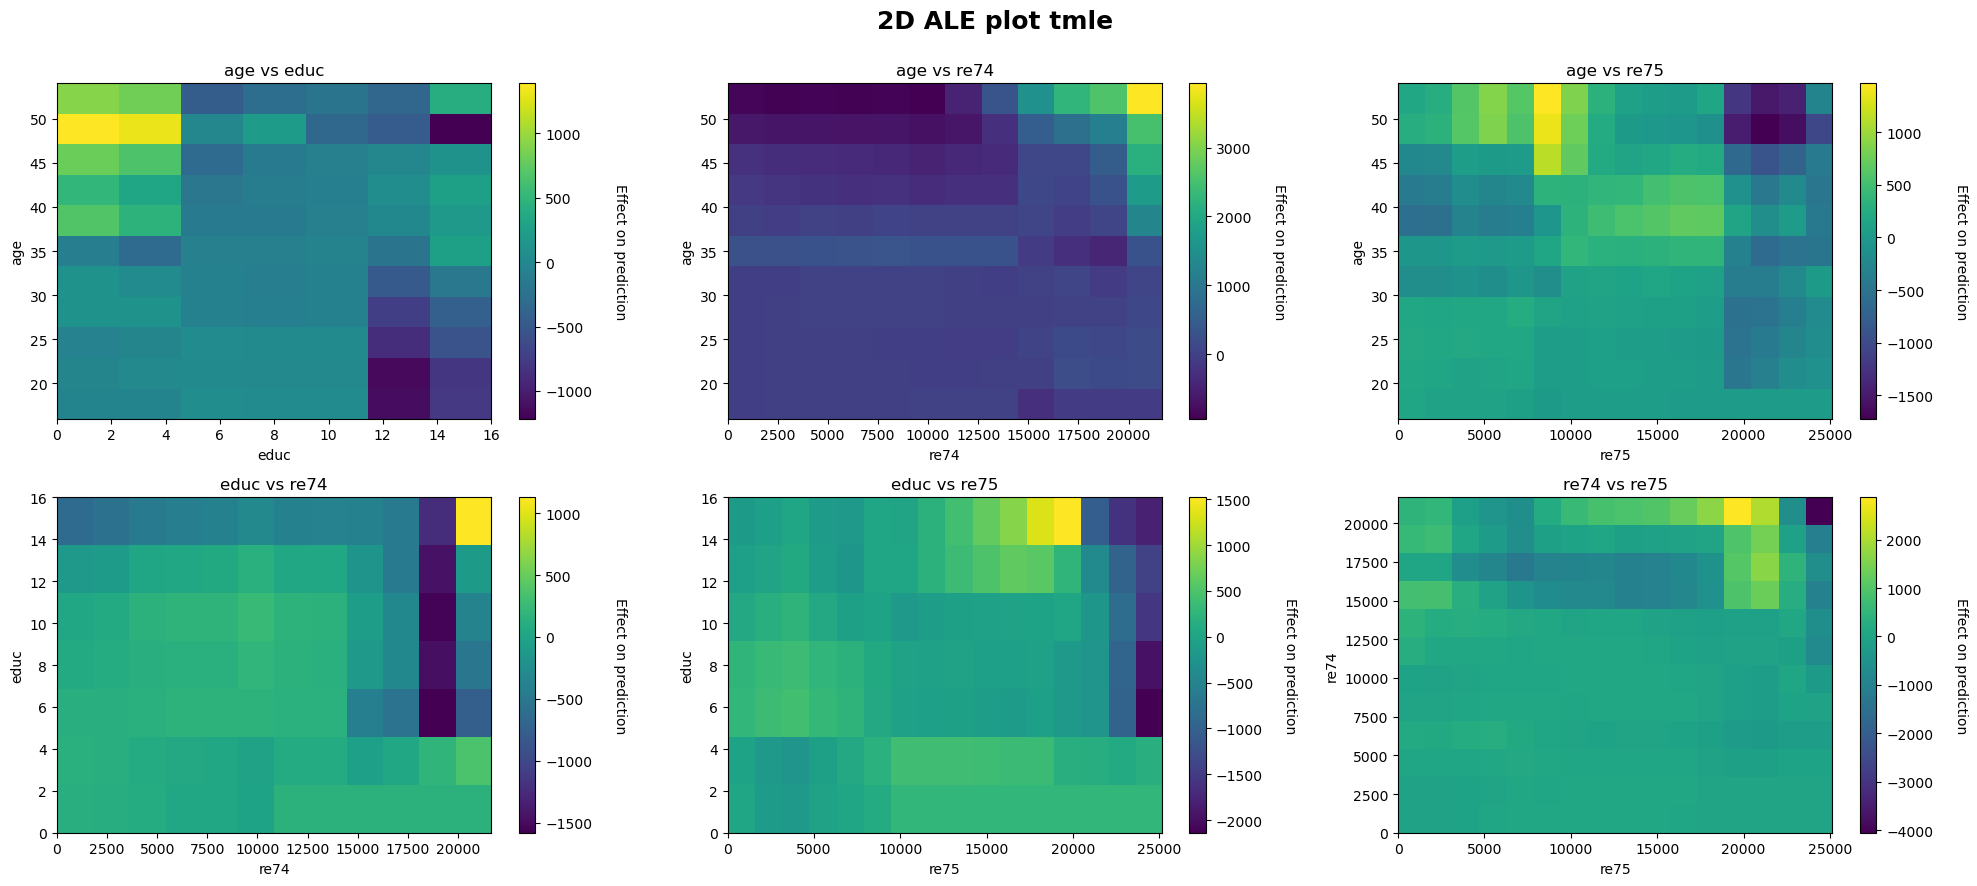

In [20]:
# 1. Definizione X e y
best_features = ['age', 'educ', 're74', 're75']
X=df[best_features]
y = df['re78'].values

# 2. Addestramento
pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)
pipe.fit(X, y)   

# 3. Creazione delle combinazioni
coppie_features = list(itertools.combinations(best_features, 2))
num_plots = len(coppie_features)

print(f"Totale combinazioni generate: {num_plots}")

# 4. Impostazione della griglia (4 colonne)
cols = 3
rows = math.ceil(num_plots / cols)

# Creiamo la figura con le dimensioni proporzionate al numero di righe
# figsize=(larghezza, altezza_per_riga * numero_righe)
fig, axes = plt.subplots(rows, cols, figsize=(20, 4.5 * rows))

# Appiattiamo la matrice degli assi (da 2D a 1D) per iterare facilmente con un singolo indice
axes = axes.flatten() 

# 5. Generazione degli ALE plot 2D nella griglia
for i, coppia in enumerate(coppie_features):
    ax = axes[i] # Selezioniamo l'asse corrente
    
    ale_eff = ale(
        X=df[best_features], 
        model=pipe,          
        feature=list(coppia),
        grid_size=20,        
        plot=True,
        fig=fig,
        ax=ax                # Passiamo l'asse specifico della griglia
    )
    
    ax.set_title(f'{coppia[0]} vs {coppia[1]}', fontsize=12)


# Aggiustiamo gli spazi per evitare che i titoli e gli assi si sovrappongano
# Aggiunge un titolo generale a tutta la griglia
fig.suptitle('2D ALE plot tmle', fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('ale_interazioni_TMLE.png', dpi=300, bbox_inches='tight')

plt.show()

---
# DEEP LEARNING

In [21]:
df_raw = pd.read_csv("df_raw.csv")
df_raw

,Unnamed: 0,trt,age,educ,black,hisp,marr,nodeg,re74,re75,re78
0,0,1.0,37.0,11.0,1.0,0.0,1.0,1.0,0.000000,0.000000,9930.046000
1,1,1.0,30.0,12.0,1.0,0.0,0.0,0.0,0.000000,0.000000,24909.450000
2,2,1.0,27.0,11.0,1.0,0.0,0.0,1.0,0.000000,0.000000,7506.146000
3,3,1.0,22.0,9.0,1.0,0.0,0.0,1.0,0.000000,0.000000,4056.494000
4,4,1.0,23.0,12.0,1.0,0.0,0.0,0.0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
14421,14421,0.0,22.0,12.0,1.0,0.0,0.0,0.0,3975.352051,6801.435059,2757.437988
14422,14422,0.0,20.0,12.0,1.0,0.0,1.0,0.0,1445.938965,11832.240234,6895.071777
14423,14423,0.0,37.0,12.0,0.0,0.0,0.0,0.0,1733.951050,1559.370972,4221.865234
14424,14424,0.0,47.0,9.0,0.0,0.0,1.0,1.0,16914.349609,11384.660156,13671.929688


In [22]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

features = ['age', 'educ', 'black', 'hisp', 'marr', 'nodeg', 're74', 're75']
X_full = df_raw[features].values
Y_full = df_raw['re78'].values
T_full = df_raw['trt'].values

# Split Train/Test
X_train_full, X_test, y_train_full, y_test, T_train_full, T_test = train_test_split(
    X_full, Y_full, T_full,
    test_size=0.2,
    stratify=T_full,
    random_state=42,
)

# Split Train/Valid
X_train, X_valid, y_train, y_valid, T_train, T_valid = train_test_split(
    X_train_full, y_train_full, T_train_full,
    test_size=0.25,  # ratio 
    stratify=T_train_full,
    random_state=42,
)

print(f"Train: {len(X_train)} osservazioni")
print(f"Valid: {len(X_valid)} osservazioni")
print(f"Test:  {len(X_test)} osservazioni")

# Fit pd the scalers indipendently
scaler_X = StandardScaler().fit(X_train)
scaler_y = MinMaxScaler().fit(y_train.reshape(-1, 1))

X_train_s = scaler_X.transform(X_train)
X_valid_s = scaler_X.transform(X_valid)
X_test_s  = scaler_X.transform(X_test)

y_train_s = scaler_y.transform(y_train.reshape(-1, 1)).ravel()
y_valid_s = scaler_y.transform(y_valid.reshape(-1, 1)).ravel()
y_test_s  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

# 4. Bootstrap only on the training
N_BOOTSTRAP = 2  # moltiplication factor

X_train_boot, y_train_boot, T_train_boot = [], [], []
for i in range(N_BOOTSTRAP):
    X_b, y_b, T_b = resample(
        X_train_s, y_train_s, T_train,
        replace=True,
        n_samples=len(X_train_s),
        random_state=42 + i,  # change seeds every rounds
        stratify=T_train,     # keep Tretment ratio
    )
    X_train_boot.append(X_b)
    y_train_boot.append(y_b)
    T_train_boot.append(T_b)

X_train_boot = np.vstack(X_train_boot)
y_train_boot = np.concatenate(y_train_boot)
T_train_boot = np.concatenate(T_train_boot)

print(f"Train bootstrap: {len(X_train_boot)} osservazioni (x{N_BOOTSTRAP})")

# Add the Tretement vector 
X_train_model = np.column_stack([X_train_boot, T_train_boot])
X_valid_model = np.column_stack([X_valid_s, T_valid])
X_test_model  = np.column_stack([X_test_s,  T_test])

Train: 8655 osservazioni
Valid: 2885 osservazioni
Test:  2886 osservazioni
Train bootstrap: 17310 osservazioni (x2)


In [23]:
Y_full_s = scaler_y.transform(Y_full.reshape(-1, 1)).ravel()

In [24]:

import pandas as pd

def grid_search_propensity_score(X, T, pca_options, reg_covar_options, cov_type_options,
                                  n_components_treated_options, n_components_control_options):

    results = []
    X_preprocessed = preprocess_pca(X)   
    
    print('Grid search ...')
    for n_pca in pca_options:
      
        pca_test = PCA(n_components=n_pca, random_state=42)
        X_pca_test = pca_test.fit_transform(X_preprocessed)
        var_explained = pca_test.explained_variance_ratio_.sum()

        X1 = X_pca_test[T == 1]
        X0 = X_pca_test[T == 0]

        
        for reg_covar, cov_type, n_comp_t, n_comp_c in itertools.product(
            reg_covar_options, cov_type_options,n_components_treated_options, n_components_control_options):

            
            # print(f'La combinazione provata è {n_pca, reg_covar, cov_type, n_comp_t, n_comp_c}')
    
            try:
                e_hat_test, gmm1_test, gmm0_test = gmm_propensity_score(
                    X_pca_test, T,
                    n_components_treated=n_comp_t,
                    n_components_control=n_comp_c,
                    clip=0.0,
                    reg_covar=reg_covar,
                    cov_type=cov_type,
                )
            except Exception:
                continue

            overlap = ((e_hat_test > 0.1) & (e_hat_test < 0.9)).sum()

            results.append({
                'n_pca': n_pca, 'reg_covar': reg_covar, 'cov_type': cov_type,
                'n_components_treated': n_comp_t, 'n_components_control': n_comp_c,
                'overlap': overlap, 'e_hat_std': e_hat_test.std(),
                'var_explained_pca': var_explained,
                'bic_treated': gmm1_test.bic(X1),
                'bic_control': gmm0_test.bic(X0),
            })

    return pd.DataFrame(results).sort_values('overlap', ascending=False)

In [25]:
pca_options = [2, 3, 4, 5]
reg_covar_options = [1e-3, 1e-2, 5e-2, 1e-1, 5e-1]
cov_type_options = ['diag', 'tied', 'spherical']
n_components_treated_options=[1, 2]     # tieni basso, hai solo 185 trattati
n_components_control_options=[1, 2, 3, 5]

result = grid_search_propensity_score(df_raw[features], df_raw['trt'].values, pca_options, reg_covar_options, cov_type_options,n_components_treated_options, n_components_control_options )
print(result.head())

Grid search ...
     n_pca  reg_covar cov_type  n_components_treated  n_components_control  \
252      4      0.001     tied                     2                     1   
372      5      0.001     tied                     2                     1   
373      5      0.001     tied                     2                     2   
374      5      0.001     tied                     2                     3   
253      4      0.001     tied                     2                     2   

     overlap  e_hat_std  var_explained_pca  bic_treated    bic_control  
252     1805   0.208808           0.784187   606.803435  181429.901539  
372     1698   0.207849           0.879916   865.518893  218251.408681  
373     1452   0.206076           0.879916   865.518893  215053.944482  
374     1419   0.210947           0.879916   865.518893  212856.334878  
253     1360   0.210716           0.784187   606.803435  179288.630917  


In [26]:
BEST_N_PCA = 4
BEST_REG_COVAR = 0.001
BEST_COV_TYPE = 'tied'
BEST_COMP_TRT = 2
BEST_COMP_CNTR = 1

pca_best = PCA(n_components=BEST_N_PCA, random_state=42)
X_pca_best = pca_best.fit_transform(preprocess_pca(df_raw[features]))

e_hat, gmm1_final, gmm0_final = gmm_propensity_score(
    X_pca_best,  df_raw['trt'].values,
    n_components_treated= BEST_COMP_TRT,
    n_components_control= BEST_COMP_CNTR,
    clip=0.05,
    reg_covar=BEST_REG_COVAR,
    cov_type=BEST_COV_TYPE,
)
H = np.where(T_full == 1, 1 / e_hat, -1 / (1 - e_hat))
H1 = 1 / e_hat            # H(T=1, X)
H0 = -1 / (1 - e_hat)     # H(T=0, X)
print(f"H range: [{H.min():.2f}, {H.max():.2f}]")

H range: [-20.00, 20.00]


In [37]:
# model = keras.models.Sequential([
#     keras.layers.Input(shape=X_train_model.shape[1:]),
#     keras.layers.Dense(16, activation='relu'),
#     keras.layers.Dropout(0.2),          # dropout 
#     keras.layers.Dense(8, activation='relu'),
#     keras.layers.Dropout(0.2),
#     keras.layers.Dense(4, activation='relu'),
#     keras.layers.Dense(1, activation='sigmoid') # force output in (0,1)
# ])

# model.compile(loss="mse", optimizer="adam", metrics=["mae"]) 


# early_stop = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

# history = model.fit(
#     X_train_model, y_train_boot,     
#     epochs=50,
#     validation_data=(X_valid_model, y_valid_s),  
#     callbacks=[early_stop],
# )

In [28]:
# model.save("TMLE_model_bootstrap.keras")

In [29]:
# model = keras.models.load_model("tmle_outcome_model.keras")
model = keras.models.load_model("TMLE_model_bootstrap.keras")

In [30]:
model.evaluate(X_test_model, y_test_s)

91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0142 - mae: 0.0949


In [31]:
from scipy.special import logit

# 1. Scala X_full con lo STESSO scaler fittato sul training
X_full_s = scaler_X.transform(X_full)

X0 = np.column_stack([X_full_s, np.zeros(len(X_full_s))])
X1 = np.column_stack([X_full_s, np.ones(len(X_full_s))])
Xt = np.column_stack([X_full_s, T_full])

y0 = model.predict(X0).flatten()
y1 = model.predict(X1).flatten()
y_t = model.predict(Xt).flatten()

print(f"y_t range: [{y_t.min():.4f}, {y_t.max():.4f}]")
print(f"y1 range: [{y1.min():.4f}, {y1.max():.4f}]")
print(f"y0 range: [{y0.min():.4f}, {y0.max():.4f}]")
print(f"NaN in logit(y_t): {np.isnan(logit(y_t)).sum()}")

451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
y_t range: [0.0400, 0.3742]
y1 range: [0.0336, 0.3728]
y0 range: [0.0400, 0.3742]
NaN in logit(y_t): 0


In [32]:
from scipy.special import expit, logit
import statsmodels.api as sm

offset = logit(y_t)
Y_full_s = scaler_y.transform(Y_full.reshape(-1,1)).ravel()

fluct_model = sm.GLM(Y_full_s, H.reshape(-1, 1),
                      family=sm.families.Binomial(),
                      offset=offset)
fluct_res = fluct_model.fit()
eps_hat = fluct_res.params[0]

In [33]:
y_t_star = expit(logit(y_t) + eps_hat * H)
y0_star = expit(logit(y0) + eps_hat * H0)
y1_star = expit(logit(y1) + eps_hat * H1)
tau_ate_scaled = np.mean(y1_star - y0_star)

In [34]:
y_scaled = scaler_y.transform(df_raw['re78'].values.reshape(-1, 1)).ravel()
IF = (y_scaled - y_t_star) * H + (y1_star - y0_star) - tau_ate_scaled

y_range = scaler_y.data_max_[0] - scaler_y.data_min_[0]
tau_ate_DL = tau_ate_scaled * y_range
SE = np.sqrt(np.var(IF) / len(IF)) * y_range

CI_lower = tau_ate_DL - 1.96 * SE
CI_upper = tau_ate_DL + 1.96 * SE

print(f'TMLE of ATE (DL): {tau_ate_DL:.2f}')
print(f"SE:       {SE:,.0f} $")
print(f"CI 95%:   [{CI_lower:,.0f}, {CI_upper:,.0f}] $")

TMLE of ATE (DL): 1773.69
SE:       190 $
CI 95%:   [1,401, 2,147] $


In [35]:
naive = df.loc[df_raw['trt']==1, 're78'].mean() - df.loc[df_raw['trt']==0, 're78'].mean()
print(f"Naive diff-in-means: {naive: .2f}")

Naive diff-in-means: -864.95


451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


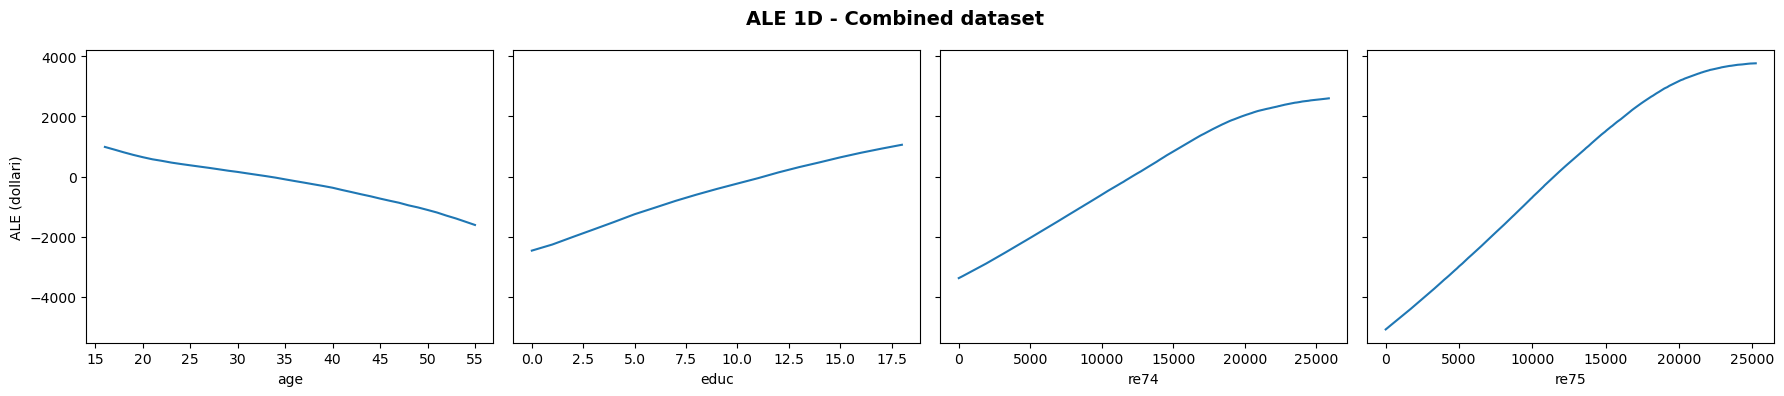

In [38]:
features      = ['age', 'educ', 'black', 'hisp', 'marr', 'nodeg', 're74', 're75']
best_features = ['age', 'educ', 're74', 're75']
cols = features + ['trt']                                  # column order expected by the Keras model (T last)
y_range = scaler_y.data_max_[0] - scaler_y.data_min_[0]    # rescales the [0,1] output back to dollars

# Whole dataset (treated + controls), treatment kept at its observed value
X_m = np.column_stack([scaler_X.transform(df_raw[features].values), df_raw['trt'].values])

explainer = ALE(model.predict, feature_names=cols, target_names=['re78_scaled'])
# ALE only for the selected features (by column index)
exp = explainer.explain(X_m, features=[cols.index(f) for f in best_features])

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

for ax, name, grid, ale_v in zip(axes, best_features, exp.feature_values, exp.ale_values):
    j = features.index(name)
    # x: grid back to original units (years / dollars); y: ALE in dollars
    ax.plot(grid * scaler_X.scale_[j] + scaler_X.mean_[j], ale_v[:, 0] * y_range)
    ax.set_xlabel(name)
axes[0].set_ylabel('ALE (dollari)')

fig.suptitle('ALE 1D - Combined dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('ale_interazioni_NN.png', dpi=300, bbox_inches='tight')

plt.show()

# CONCLUSION
Against the experimental benchmark of 1,794.34 (LaLonde, 1986; Chen et al., 2024), both TMLE estimates (DL: 1,773.69; ML: 194.30) land closer to the truth than the plain AIPW estimate (ATE: 90.22), so the semiparametric targeting step improved the estimates on this dataset. The DL pipeline, which uses the full PSID population and augments the stratified training set with bootstrap resampling, is the best in absolute terms, with a bias of about 20 $ from the benchmark. It is also the best once estimation variance is taken into account, as the only 95% interval that excludes zero ([1,401, 2,147]) and contains the experimental value, whereas the ML-based intervals include zero. This ranking is only verifiable because the experimental result is known: without a benchmark, closeness to the truth could not be used to select an estimator.